In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

In [2]:
file = '/global/scratch/users/toireasamarie/0.1x0.1_deg_gridded_datasets/final_datasets/a10_lowCF_scaled_7day_events_long.parquet'
events_long = pd.read_parquet(file, engine='pyarrow')

In [3]:
events_long

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30128,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,3,NaN,0.440964,0.193836,0.014792,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30129,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,4,NaN,0.393795,0.173095,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30130,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,5,9.124734e+14,0.368646,0.162024,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30131,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,6,1.082669e+15,0.355016,0.156042,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing


In [4]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'pct_clay',
       'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='object')

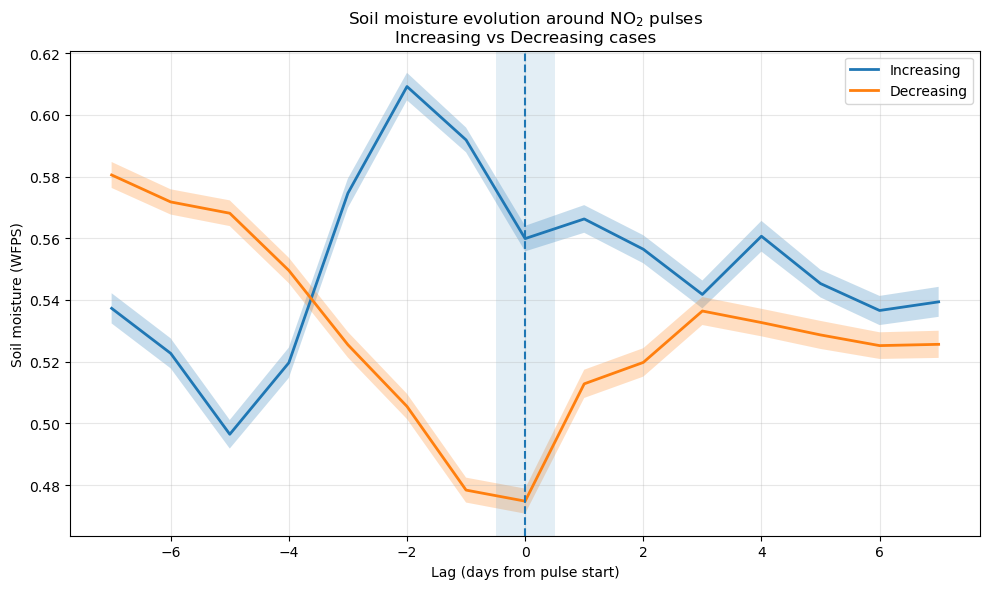

In [5]:
plot_df = events_long.copy()

#keep only the two classes you want
plot_df = plot_df[plot_df["sm_class"].isin(["increasing", "decreasing"])].copy()

#drop missing values needed for plotting
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])


#compute mean +SEM by lag
summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"]
           .agg(["mean", "std", "count"]).reset_index())

summary["sem"] = summary["std"] / np.sqrt(summary["count"])

#split out the two classes
inc = summary[summary["sm_class"] == "increasing"].copy()
dec = summary[summary["sm_class"] == "decreasing"].copy()

#plot
fig, ax = plt.subplots(figsize=(10, 6))

#increasing
ax.plot(inc["lag_days"], inc["mean"], label="Increasing", linewidth=2)
ax.fill_between(inc["lag_days"], inc["mean"] -inc["sem"], inc["mean"] +inc["sem"],
                alpha=0.25)

#decreasing
ax.plot(dec["lag_days"], dec["mean"], label="Decreasing",linewidth=2)
ax.fill_between(dec["lag_days"],dec["mean"] - dec["sem"],dec["mean"] + dec["sem"], alpha=0.25)

#pulse day marker
ax.axvline(0, linestyle="--", linewidth=1.5)
ax.axvspan(-0.5, 0.5, alpha=0.12)

ax.set_xlabel("Lag (days from pulse start)")
ax.set_ylabel("Soil moisture (WFPS)")
ax.set_title("Soil moisture evolution around NO$_2$ pulses\nIncreasing vs Decreasing cases")
ax.legend()
ax.grid(True, alpha=0.3)

plt.tight_layout()
plt.show()

In [6]:
#soil groups
soil_cols = ["pct_clay", "pct_clay_loam", "pct_loam", "pct_loamy_sand",
             "pct_sand", "pct_sandy_clay", "pct_sandy_clay_loam",
             "pct_sandy_loam", "pct_silt", "pct_silt_loam",
             "pct_silty_clay", "pct_silty_clay_loam"]

df = events_long.copy()

# dominant soil type per row
df["dominant_soil"] = df[soil_cols].idxmax(axis=1).str.replace("pct_", "")
df["max_frac"] = df[soil_cols].max(axis=1)

#endmember filter, must have >70% per cell 
threshold = 0.70
df_endmembers = df[df["max_frac"] >= threshold].copy()

counts =df_endmembers["dominant_soil"].value_counts()
keep_soils =counts[counts >50].index
df_endmembers =df_endmembers[df_endmembers["dominant_soil"].isin(keep_soils)].copy()

#map to soil groups 
soil_group_map = {
    "sand": "coarse",
    
    "loamy_sand": "moderately_coarse",
    "sandy_loam": "moderately_coarse",
    
    "loam": "medium",
    "silt_loam": "medium",
    "silt":"medium",
    
    "clay_loam":"fine",
    "silty_clay_loam":"fine",
    "sandy_clay_loam":"fine",
    "clay":"fine",
    "silty_clay":"fine",
    "sandy_clay": "fine",}

df_endmembers["soil_group"] =df_endmembers["dominant_soil"].map(soil_group_map)

df_end = df_endmembers[
    df_endmembers["soil_group"].notna() &
    df_endmembers["sm_class"].isin(["increasing", "decreasing"])
].dropna(subset=["lag_days", "WFPS_c"]).copy()

soil_group_order = ["coarse", "moderately_coarse", "medium", "fine"]
group_palette = {"coarse": "blue",
                 "moderately_coarse": "green",
                 "medium":"darkgoldenrod",
                 "fine": "red"}

print("Events per soil group × sm_class:")
print(df_end.groupby(["soil_group", "sm_class"])["event_id"].nunique().unstack())

Events per soil group × sm_class:
sm_class           decreasing  increasing
soil_group                               
coarse                     10           8
fine                      338         209
medium                    833         501
moderately_coarse          64          46


In [7]:
#event counts table 
event_counts = (df_end.groupby(["soil_group", "sm_class"])["event_id"]
                .nunique().unstack().reindex(soil_group_order).fillna(0))

for col in ["increasing", "decreasing"]:
    if col not in event_counts.columns:
        event_counts[col] = 0

event_counts =event_counts[["increasing", "decreasing"]]
event_counts["Total"] =event_counts["increasing"] + event_counts["decreasing"]

event_counts["Inc %"] = np.where(
    event_counts["Total"] >0,
    100 * event_counts["increasing"] /event_counts["Total"],
    np.nan)

event_counts["Dec %"] = np.where(
    event_counts["Total"] > 0,
    100 * event_counts["decreasing"] /event_counts["Total"],
    np.nan)


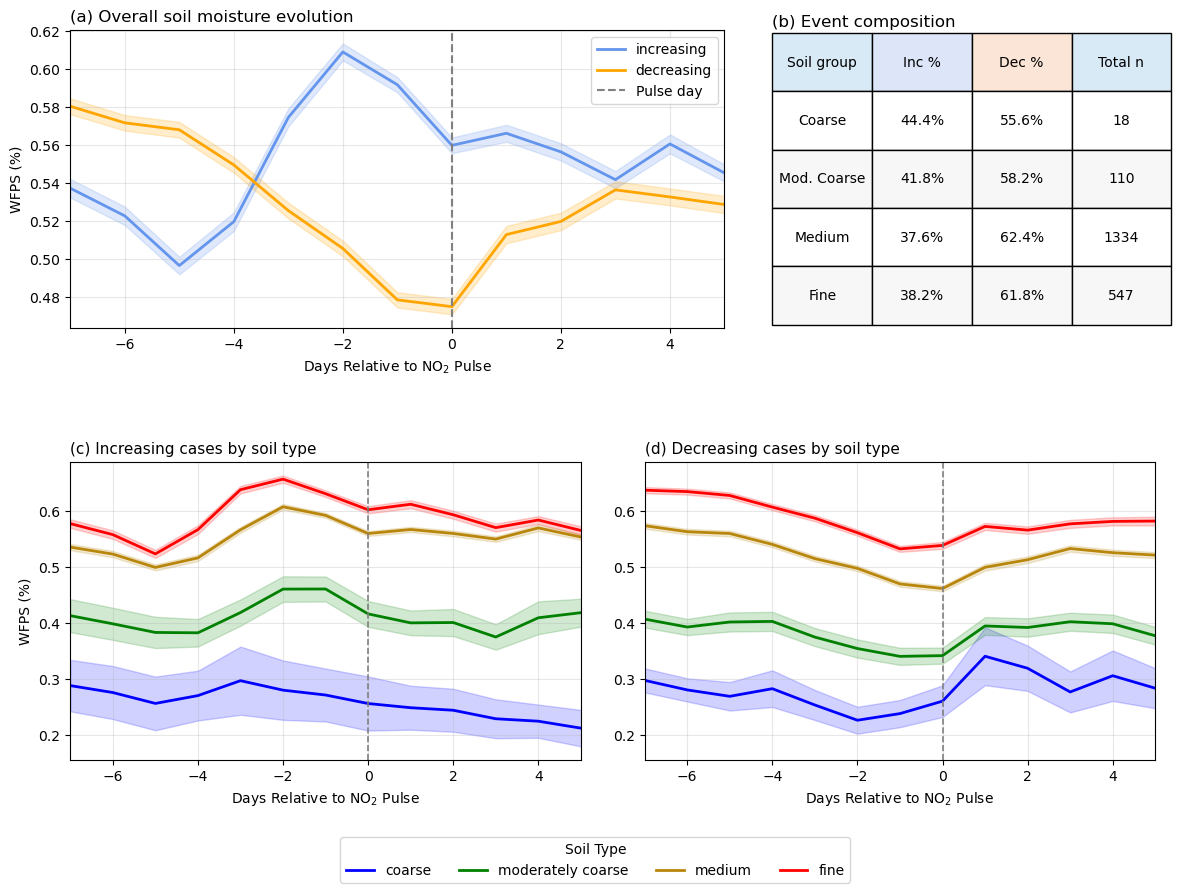

In [8]:
fig = plt.figure(figsize=(14, 10))

gs = fig.add_gridspec(2, 8, hspace=0.45, wspace=0.8, 
                      height_ratios=[1, 1])

ax1 = fig.add_subplot(gs[0, 0:5]) #a- overall figure
ax2 = fig.add_subplot(gs[0, 6])   #b- table
ax3 = fig.add_subplot(gs[1, 0:4]) #c- increasing
ax4 = fig.add_subplot(gs[1, 4:8])  #d- decreasing

sm_colors = {"increasing": "cornflowerblue", "decreasing": "orange"}

#panel a-- the overall SM figure
plot_df = events_long[events_long["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])

summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"]
           .agg(["mean", "std", "count"])
           .reset_index())
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

for cls in ["increasing", "decreasing"]:
    sub = summary[summary["sm_class"] == cls]
    ax1.plot(sub["lag_days"], sub["mean"], label=cls, color=sm_colors[cls], linewidth=2)
    ax1.fill_between(sub["lag_days"], sub["mean"] - sub["sem"], sub["mean"] + sub["sem"],
                     color=sm_colors[cls], alpha=0.20)

ax1.axvline(0, linestyle="--", linewidth=1.5, color="gray", label="Pulse day")
ax1.set_xlim(-7, 5)
ax1.set_xlabel("Days Relative to NO$_2$ Pulse")
ax1.set_ylabel("WFPS (%)")
ax1.set_title("(a) Overall soil moisture evolution", fontsize=12, loc="left")
ax1.legend(fontsize=10)
ax1.grid(True, alpha=0.3)

#panels c and d-- splitting up by soil type groups
for ax, cls, label in [
    (ax3, "increasing", "(c) Increasing cases by soil type"),
    (ax4, "decreasing", "(d) Decreasing cases by soil type"),
]:
    sub_df = df_end[df_end["sm_class"] == cls].copy()
    soil_summary = sub_df.groupby(["soil_group", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index()
    soil_summary["sem"] = soil_summary["std"] / np.sqrt(soil_summary["count"])

    for grp in soil_group_order:
        grp_sub = soil_summary[soil_summary["soil_group"] == grp]
        if grp_sub.empty:
            continue
        ax.plot(grp_sub["lag_days"], grp_sub["mean"],
                color=group_palette[grp], linewidth=2,
                label=grp.replace("_", " "))
        ax.fill_between(grp_sub["lag_days"],
                        grp_sub["mean"] - grp_sub["sem"],
                        grp_sub["mean"] + grp_sub["sem"],
                        color=group_palette[grp], alpha=0.18)

    ax.axvline(0, linestyle="--", linewidth=1.2, color="gray")
    ax.set_xlim(-7, 5)
    ax.set_title(label, fontsize=11, loc="left")
    ax.set_xlabel("Days Relative to NO$_2$ Pulse", fontsize=10)
    ax.set_ylabel("WFPS (%)", fontsize=10)
    ax.grid(True, alpha=0.3)

#match the y axis and a shared legend 
y_min = min(ax3.get_ylim()[0], ax4.get_ylim()[0])
y_max = max(ax3.get_ylim()[1], ax4.get_ylim()[1])
ax3.set_ylim(y_min, y_max)
ax4.set_ylim(y_min, y_max)
ax4.set_ylabel("")

handles, labels = ax3.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=len(labels),
           bbox_to_anchor=(0.5, 0.02), fontsize=10, title="Soil Type")

plt.subplots_adjust(bottom=0.15)

#panel b is the table of increasing/decreasing
soil_label_map = {"coarse": "Coarse",
                  "moderately_coarse": "Mod. Coarse", #need to abbreviate to fit on the table 
                  "medium": "Medium",
                  "fine": "Fine"}

table_df_simple = pd.DataFrame({
    "Soil group": [soil_label_map.get(g, g.replace("_", " ").title()) for g in event_counts.index],
    "Inc %": [f"{x:.1f}%" if pd.notnull(x) else "—" for x in event_counts["Inc %"]],
    "Dec %":[f"{x:.1f}%" if pd.notnull(x) else "—" for x in event_counts["Dec %"]],
    "Total n": event_counts["Total"].astype(int).values})

ax2.axis("off")
ax2.text(-2, 1.05, "(b) Event composition",
         transform=ax2.transAxes,
         fontsize=12, fontweight='normal',
         va='top', ha='left')

table = ax2.table(cellText=table_df_simple.values,
                  colLabels=table_df_simple.columns,
                  loc="center", cellLoc="center")

table.auto_set_font_size(False)
table.set_fontsize(10)
table.scale(5, 3.5)

for (row, col), cell in table.get_celld().items():
    if row == 0:
        cell.set_text_props(weight="normal")
        cell.set_facecolor("#D9EAF7")
        if col == 1: cell.set_facecolor("#DCE6F8")
        if col == 2: cell.set_facecolor("#FBE5D6")
    else:
        cell.set_facecolor("#F7F7F7" if row % 2 == 0 else "white")

plt.savefig('/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/Soil Moisture Evolution wsoiltype', dpi=300)
plt.show()


# saving for pnas

Getting rid of the table and decided to put a table in the paper itself instead

In [9]:
import matplotlib.font_manager as fm

In [10]:
#PNAS figure settings
cm = 1 /2.54

# PNAS widths-- same as text column = 8.7 cm, medium wide = 11.4 cm, full wide = 17.8 cm
fig_width = 8.7 *cm
fig_height = 18 *cm

plt.rcParams.update(plt.rcParamsDefault)

plt.rcParams.update({
    #font sizes should be 6–12 pt according to template
    "font.size": 7,
    "axes.labelsize": 7,
    "axes.titlesize": 8,
    "xtick.labelsize": 6,
    "ytick.labelsize": 6,
    "legend.fontsize": 6,

    #font embedding for pdf/eps
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    
    "svg.fonttype": "none",
    "savefig.dpi": 600,
})

The PostScript backend does not support transparency; partially transparent artists will be rendered opaque.


Saved: sm_evolution_w_soiltype .pdf / .eps / .png


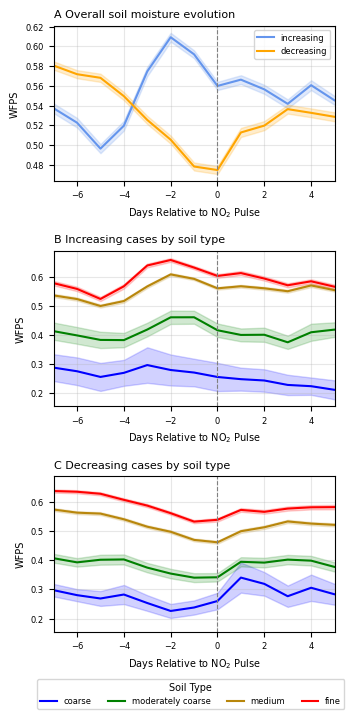

In [11]:
fig, (ax1, ax3, ax4) = plt.subplots(3, 1, figsize=(fig_width, fig_height))
fig.subplots_adjust(hspace=0.45)

sm_colors = {"increasing": "cornflowerblue", "decreasing": "orange"}

#panel a-- the overall SM figure
plot_df = events_long[events_long["sm_class"].isin(["increasing", "decreasing"])].copy()
plot_df = plot_df.dropna(subset=["lag_days", "WFPS_c", "sm_class"])
summary = (plot_df.groupby(["sm_class", "lag_days"])["WFPS_c"]
           .agg(["mean", "std", "count"]).reset_index())
summary["sem"] = summary["std"] / np.sqrt(summary["count"])

for cls in ["increasing", "decreasing"]:
    sub = summary[summary["sm_class"] == cls]
    ax1.plot(sub["lag_days"], sub["mean"], label=cls, color=sm_colors[cls], linewidth=1.5)
    ax1.fill_between(sub["lag_days"], sub["mean"] - sub["sem"], sub["mean"] + sub["sem"],
                     color=sm_colors[cls], alpha=0.20)

ax1.axvline(0, linestyle="--", linewidth=0.8, color="gray") # label="Pulse day")
ax1.set_xlim(-7, 5)
ax1.set_xlabel("Days Relative to NO$_2$ Pulse")
ax1.set_ylabel("WFPS")
ax1.set_title("A Overall soil moisture evolution", loc="left")
ax1.legend()
ax1.grid(True, alpha=0.3)

#panels b and c-- splitting up by soil type groups
for ax, cls, label in [
    (ax3, "increasing", "B Increasing cases by soil type"),
    (ax4, "decreasing", "C Decreasing cases by soil type"),
]:
    sub_df = df_end[df_end["sm_class"] == cls].copy()
    soil_summary = sub_df.groupby(["soil_group", "lag_days"])["WFPS_c"].agg(["mean", "std", "count"]).reset_index()
    soil_summary["sem"] = soil_summary["std"] / np.sqrt(soil_summary["count"])

    for grp in soil_group_order:
        grp_sub = soil_summary[soil_summary["soil_group"] == grp]
        if grp_sub.empty:
            continue
        ax.plot(grp_sub["lag_days"], grp_sub["mean"],
                color=group_palette[grp], linewidth=1.5,
                label=grp.replace("_", " "))
        ax.fill_between(grp_sub["lag_days"],
                        grp_sub["mean"] - grp_sub["sem"],
                        grp_sub["mean"] + grp_sub["sem"],
                        color=group_palette[grp], alpha=0.18)

    ax.axvline(0, linestyle="--", linewidth=0.8, color="gray")
    ax.set_xlim(-7, 5)
    ax.set_title(label, loc="left")
    ax.set_xlabel("Days Relative to NO$_2$ Pulse")
    ax.set_ylabel("WFPS")
    ax.grid(True, alpha=0.3)

#match the y axis and a shared legend 
y_min = min(ax3.get_ylim()[0], ax4.get_ylim()[0])
y_max = max(ax3.get_ylim()[1], ax4.get_ylim()[1])
ax3.set_ylim(y_min, y_max)
ax4.set_ylim(y_min, y_max)
fig.subplots_adjust(bottom=0.115, top=0.97, left=0.15, right=0.97)

handles, labels = ax3.get_legend_handles_labels()
fig.legend(handles, labels, loc='lower center', ncol=4,
           bbox_to_anchor=(0.55, 0.0), title="Soil Type")

#save
base = "/global/home/users/toireasamarie/FINAL Paper Workflow/Paper Figures/sm_evolution_w_soiltype"
fig.savefig(base +".pdf", bbox_inches="tight")
fig.savefig(base +".eps", bbox_inches="tight")
fig.savefig(base +".png", dpi=600, bbox_inches="tight")
print("Saved: sm_evolution_w_soiltype .pdf / .eps / .png")
plt.show()

In [38]:
events_long

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30128,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,3,NaN,0.440964,0.193836,0.014792,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30129,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,4,NaN,0.393795,0.173095,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30130,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,5,9.124734e+14,0.368646,0.162024,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30131,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,6,1.082669e+15,0.355016,0.156042,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing


In [39]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'pct_clay',
       'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='object')

In [41]:
import matplotlib.lines as mlines

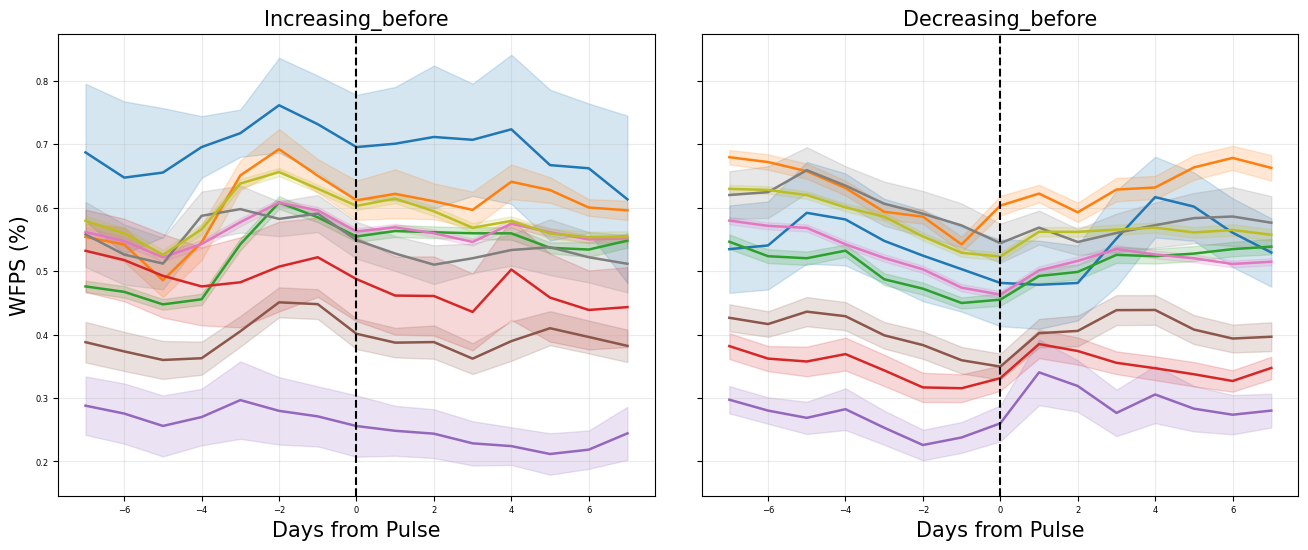

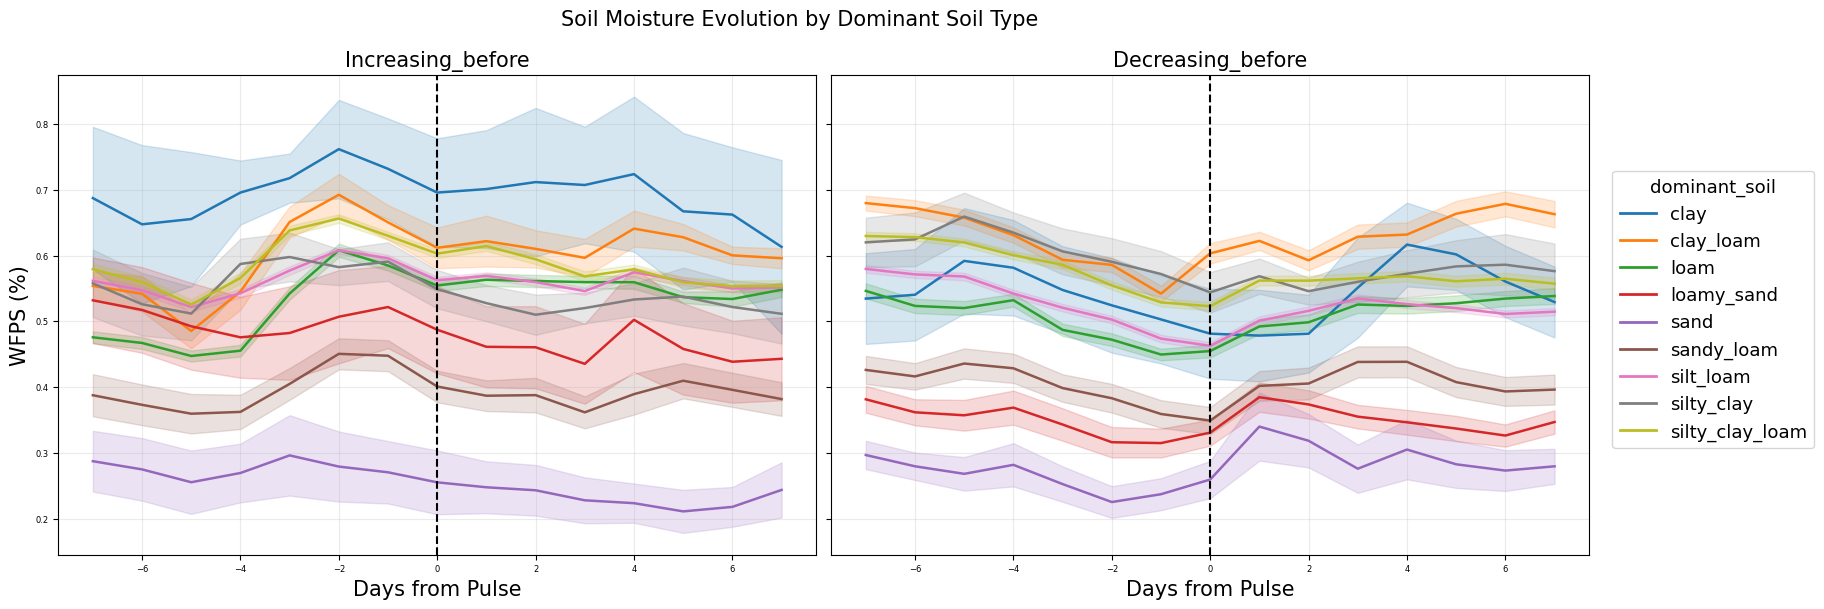

In [42]:
#increasing and decreasing cases by dominant soil type 

soil_cols = [
    "pct_clay", "pct_clay_loam", "pct_loam", "pct_loamy_sand",
    "pct_sand", "pct_sandy_clay", "pct_sandy_clay_loam",
    "pct_sandy_loam", "pct_silt", "pct_silt_loam",
    "pct_silty_clay", "pct_silty_clay_loam"
]

df = events_long.copy()
df["dominant_soil"] = df[soil_cols].idxmax(axis=1).str.replace("pct_", "")
df["max_frac"] = df[soil_cols].max(axis=1)

threshold = 0.70
df_endmembers = df[df["max_frac"] >= threshold].copy()
counts = df_endmembers["dominant_soil"].value_counts()
keep_soils = counts[counts > 50].index
df_endmembers = df_endmembers[df_endmembers["dominant_soil"].isin(keep_soils)].copy()

df_soil = df_endmembers[df_endmembers["sm_class"].isin(["increasing", "decreasing"])].dropna(subset=["lag_days", "WFPS_c"]).copy()
soil_types = sorted(df_soil["dominant_soil"].unique())

cmap = plt.get_cmap("tab10")
soil_palette = {soil: cmap(i % 10) for i, soil in enumerate(soil_types)}

soil_summary = (df_soil.groupby(["sm_class", "dominant_soil", "lag_days"])["WFPS_c"]
                .agg(["mean", "std", "count"])
                .reset_index())
soil_summary["sem"] = soil_summary["std"] / np.sqrt(soil_summary["count"])

#fig setup
fig, axes = plt.subplots(1, 2, figsize=(16, 6), sharey=True)
fig.subplots_adjust(wspace=0.08)

panel_labels = {"increasing": "Increasing_before",
                "decreasing": "Decreasing_before"}

for ax, cls in zip(axes, ["increasing", "decreasing"]):
    sub = soil_summary[soil_summary["sm_class"] == cls]

    for soil in soil_types:
        s = sub[sub["dominant_soil"] == soil]
        if s.empty:
            continue
        color = soil_palette[soil]
        ax.plot(s["lag_days"], s["mean"],
                color=color, linewidth=1.8, label=soil)
        ax.fill_between(s["lag_days"],
                        s["mean"] - s["sem"],
                        s["mean"] + s["sem"],
                        color=color, alpha=0.18)

    ax.axvline(0, linestyle="--", linewidth=1.5, color="black")
    ax.set_xlabel("Days from Pulse", fontsize=15)
    ax.set_title(panel_labels[cls], fontsize=15)
    ax.grid(True, alpha=0.25)

axes[0].set_ylabel("WFPS (%)", fontsize=15)

#shared legend 
legend_handles = [
    mlines.Line2D([], [], color=soil_palette[s], linewidth=2, label=s)
    for s in soil_types
]
fig.legend(handles=legend_handles, title="dominant_soil",  title_fontsize=13,
           fontsize=13, loc="center right",  bbox_to_anchor=(1.14, 0.5),frameon=True)

fig.suptitle("Soil Moisture Evolution by Dominant Soil Type", fontsize=15, y=1)

plt.tight_layout()
plt.show()

In [43]:
events_long

,event_id,grid_lat,grid_lon,datetime_event,pulse_date,lag_days,no2_mean,WFPS_c,sm_surface,h_precip_mm,...,pct_sandy_clay_loam,pct_sandy_loam,pct_silt,pct_silt_loam,pct_silty_clay,pct_silty_clay_loam,state_name,datetime_local,pre_slope,sm_class
0,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-7,2.013325e+15,0.275983,0.124556,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
1,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-6,NaN,0.306866,0.138481,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
2,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-5,1.832545e+15,0.254981,0.115120,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
3,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-4,NaN,0.263618,0.118996,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
4,0,36.05,-91.15,2024-04-13 15:00:00,2024-04-13,-3,NaN,0.458100,0.206703,NaN,...,0.0,0.757576,0.0,86.363636,0.757576,7.575758,Arkansas,2024-04-13 10:00:00,0.000848,increasing
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
30128,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,3,NaN,0.440964,0.193836,0.014792,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30129,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,4,NaN,0.393795,0.173095,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30130,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,5,9.124734e+14,0.368646,0.162024,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing
30131,2008,48.55,-99.85,2024-07-06 15:00:00,2024-07-06,6,1.082669e+15,0.355016,0.156042,0.000000,...,0.0,41.666667,0.0,0.000000,0.000000,0.000000,North Dakota,2024-07-06 10:00:00,-0.000573,decreasing


In [44]:
events_long.columns

Index(['event_id', 'grid_lat', 'grid_lon', 'datetime_event', 'pulse_date',
       'lag_days', 'no2_mean', 'WFPS_c', 'sm_surface', 'h_precip_mm',
       'surface_temp', 'soil_temp_layer1', 'dominant_texture', 'pct_clay',
       'pct_clay_loam', 'pct_loam', 'pct_loamy_sand', 'pct_sand',
       'pct_sandy_clay', 'pct_sandy_clay_loam', 'pct_sandy_loam', 'pct_silt',
       'pct_silt_loam', 'pct_silty_clay', 'pct_silty_clay_loam', 'state_name',
       'datetime_local', 'pre_slope', 'sm_class'],
      dtype='object')